In [1]:
# Import Libs
import xarray as xr
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import numpy as np
import xesmf as xe
from regional_mom6 import regridding as rgd
from pathlib import Path
from matplotlib.animation import FuncAnimation


In [5]:
# Define Segment Dir to Num
def segment_name(segment_number):
    return "segment_" + segment_number
def variable_name(variable, segment_number):
    return variable+"_"+segment_name(segment_number)
segment_num_to_dir = {
    "001":"south",
    "002":"north",
    "003":"east"
}
segment_dir_to_num =  {v: k for k, v in segment_num_to_dir.items()}

# Define Boundary Indexing Map
boundary_indexing_map = {}
for key in segment_dir_to_num.keys():
    if key == "north" or key == "south":
        boundary_indexing_map[key] = lambda arr: arr[0, :]
    elif key == "east" or key == "west":
        boundary_indexing_map[key] = lambda arr: arr[:, 0]
def get_coords_dict(hgrid):
    coords = {}
    for key in segment_dir_to_num.keys():
        coords[key] =  rgd.coords(hgrid, key, segment_name(key))
    return coords
def get_points_dict(hgrid: xr.Dataset):
    dict = {"u":None, "v":None, "t":None}
    for key in dict.keys():
        dict[key] = rgd.get_hgrid_arakawa_c_points(hgrid, key)
    return dict
def get_boundary_file_dict(file_dir, file_beginning, file_ending):
    bv = {}
    for key in segment_dir_to_num.keys():
        bv[key] = xr.open_dataset(Path(file_dir)/(file_beginning+segment_dir_to_num[key]+file_ending))

# Hgrids
hgrid = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/gfdl_copy.3.n3b/hgrid.nc")
gfdl_hgrid = xr.open_dataset("/glade/work/gmarques/Projects/NWA12/grid/ocean_hgrid.nc")

# Input File Path,must be in input MOM6 Structure
gfdl_boundary_conditions = ("/glade/work/gmarques/Projects/NWA12/boundary_conditions/")
rm6_boundary_conditions = ("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/gfdl_copy.3.n3b/")

# Read files & organize dicts
rm6_coords = get_coords_dict(hgrid)
gfdl_coords = get_coords_dict(gfdl_hgrid)
rm6_points = get_points_dict(hgrid)
gfdl_points = get_points_dict(gfdl_hgrid) 
gfdl_boundary_velocities = get_boundary_file_dict(gfdl_boundary_conditions,"uv_","_1993.nc" )
rm6_boundary_velocities = get_boundary_file_dict(rm6_boundary_conditions,"forcing_obc_segment_",".nc" )
gfdl_ic = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/gfdl_nwa12_data/glorys_ic_1993-01-01.nc")
regrid_ic = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/init_vel.nc")


Text(0.5, 1.0, 'Data!')

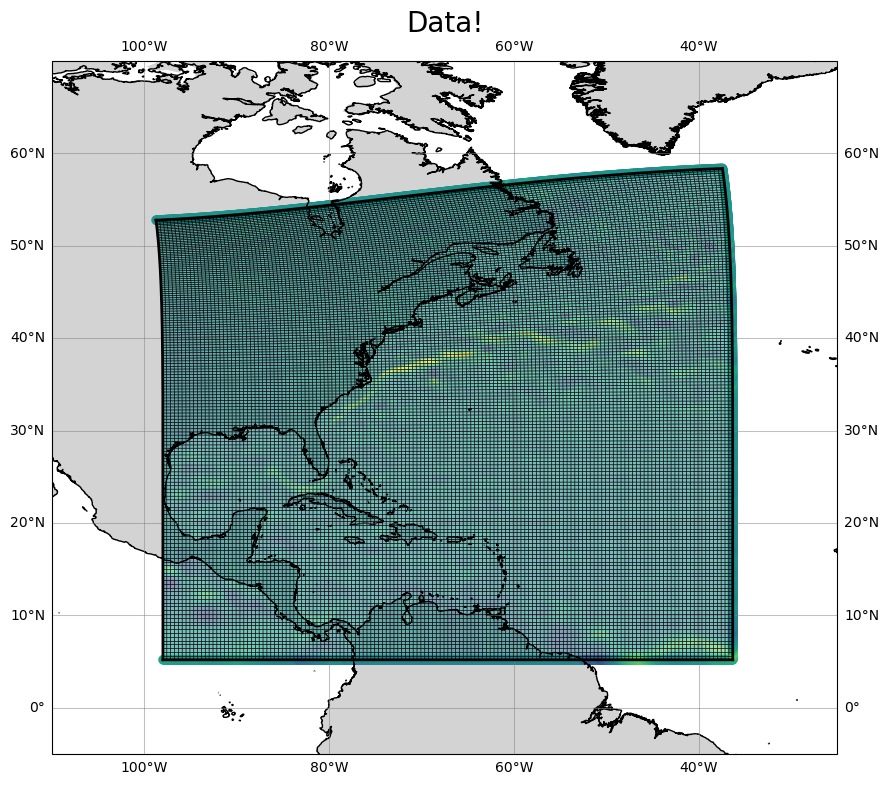

In [86]:
# Skip Factor
k = 10
variable = "u"
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# Add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
ax.coastlines(resolution='10m')  # looks better with resolution='10m'

ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
min_val = -2
max_val = 2
ax.pcolormesh(rm6_points["u"].ulon, rm6_points["u"].ulat, regrid_ic.u[0][0].values, transform=ccrs.PlateCarree(), alpha=0.6, vmin = min_val, vmax = max_val)
for key in segment_dir_to_num.keys():
    ax.scatter(rm6_coords[key].lon, rm6_coords[key].lat, c=boundary_indexing_map[key](rm6_boundary_velocities[key][variable+"_segment_"+segment_dir_to_num[key]][0][0]), transform=ccrs.PlateCarree(), alpha=0.6,vmin = min_val, vmax = max_val)
# plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('Data!'.format(k), fontsize=20)



Text(0.5, 1.0, 'GFDL Data!')

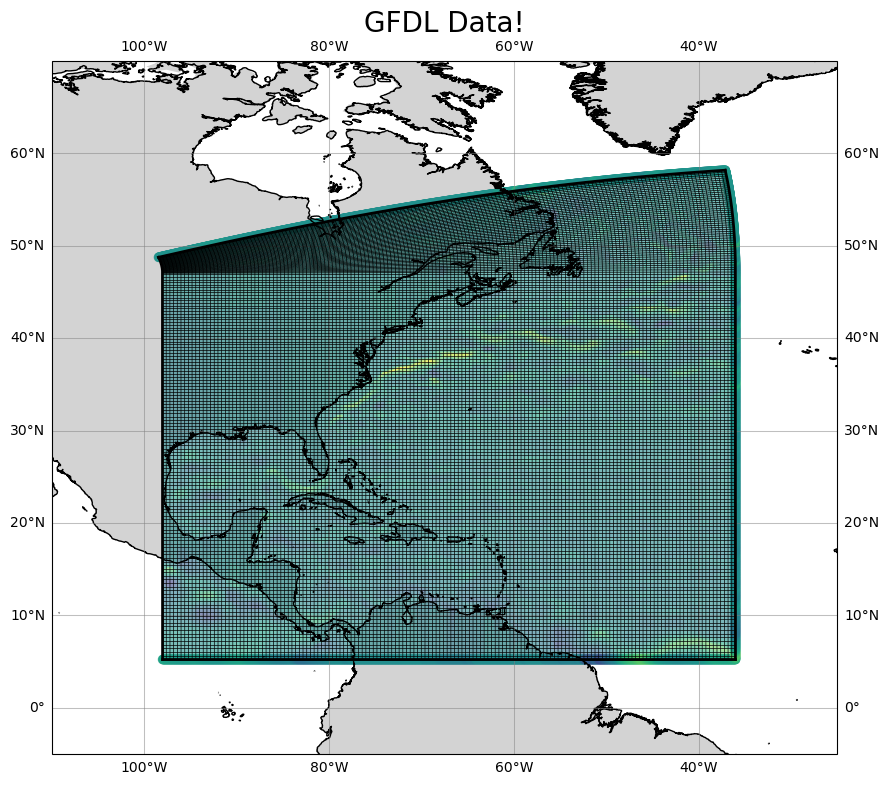

In [87]:
# Skip Factor
k = 10
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# Add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
ax.coastlines(resolution='10m')  # looks better with resolution='10m'

ax.plot(gfdl_hgrid.x[::k,::k], gfdl_hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(gfdl_hgrid.x[::k,::k].T, gfdl_hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(gfdl_hgrid.x[0,:], gfdl_hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(gfdl_hgrid.x[-1,:], gfdl_hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(gfdl_hgrid.x[:,0], gfdl_hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(gfdl_hgrid.x[:,-1], gfdl_hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())

min_val = -2
max_val = 2
ax.pcolormesh(gfdl_points["u"].ulon, gfdl_points["u"].ulat, gfdl_ic.u[0][0].values, transform=ccrs.PlateCarree(), alpha=0.6, vmin = min_val, vmax = max_val)
for key in segment_dir_to_num.keys():
    ax.scatter(gfdl_coords[key].lon, gfdl_coords[key].lat, c=boundary_indexing_map[key](gfdl_boundary_velocities[key][variable+"_segment_"+segment_dir_to_num[key]][0][0]), transform=ccrs.PlateCarree(), alpha=0.6,vmin = min_val, vmax = max_val)
# plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('GFDL Data!'.format(k), fontsize=20)



In [7]:
# Read in Output data, Output data comes with labels for t, u, and v points, but for simplicity, we'll just use ours. (Remember those come from the Hgrid)
rm6_run_dir = Path("/glade/u/home/manishrv/manish_scratch_symlink/gfdl_copy.3.n3b/run/")


In [8]:
output_file_name = Path("nwa12.test.tides.04.mom6.h.sfc.1993-01.nc")
var_name = "SSV"
output_file = xr.open_dataset(rm6_run_dir/output_file_name)

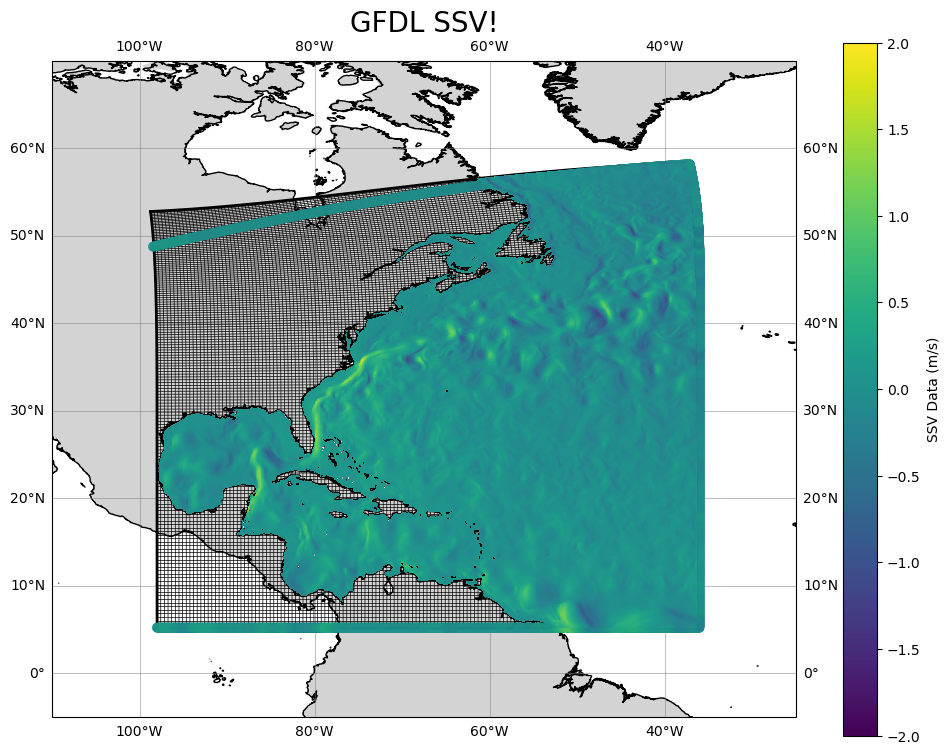

In [21]:
# Skip Factor
k = 10
variable = "v"
time = 4
# Plot and save the NWA12 Mesh grid

fig = plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# Add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
ax.coastlines(resolution='10m')  # looks better with resolution='10m'

ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
min_val = -2
max_val = 2
pcolormesh = ax.pcolormesh(rm6_points["v"].vlon, rm6_points["v"].vlat, output_file[var_name][time].values, transform=ccrs.PlateCarree(),  vmin = min_val, vmax = max_val, zorder = 3,cmap = "viridis")
plt.colorbar(pcolormesh, ax=ax, orientation='vertical', label='SSV Data (m/s)')
plt.title('GFDL SSV!'.format(k), fontsize=20)

def update_fig(time):
    pcolormesh.set_array(output_file[var_name][time].values)
    for key in segment_dir_to_num.keys():
        ax.scatter(gfdl_coords[key].lon, gfdl_coords[key].lat, c=boundary_indexing_map[key](gfdl_boundary_velocities[key][variable+"_segment_"+segment_dir_to_num[key]][time][0]), cmap = "viridis",transform=ccrs.PlateCarree(),vmin = min_val, vmax = max_val, zorder=2, alpha = 0.1)


# ani = FuncAnimation(
#     fig,
#     update_fig,
#     frames = range(5),
#     interval = 100,
#     blit = False,
#     )

# ani.save('boundary_ssv_gfdl_labeled.gif', writer='ffmpeg')

In [11]:
output_file_name = Path("nwa12.test.tides.04.mom6.h.z.1993-01.nc")
var_name_vo = "vo"
output_file = xr.open_dataset(rm6_run_dir/output_file_name)
output_file

<xarray.Dataset>
Dimensions:      (xq: 741, yh: 780, z_l: 35, z_i: 36, time: 5, nbnd: 2,
                  xh: 740, yq: 781)
Coordinates:
  * xq           (xq) float64 -98.0 -97.92 -97.83 -97.75 ... -36.5 -36.42 -36.33
  * yh           (yh) float64 5.243 5.326 5.409 5.492 ... 53.82 53.86 53.89
  * z_l          (z_l) float64 2.5 10.0 20.0 32.5 ... 5.5e+03 6e+03 6.5e+03
  * z_i          (z_i) float64 0.0 5.0 15.0 25.0 ... 5.75e+03 6.25e+03 6.75e+03
  * time         (time) object 1993-01-01 12:00:00 ... 1993-01-05 12:00:00
  * nbnd         (nbnd) float64 1.0 2.0
  * xh           (xh) float64 -97.96 -97.88 -97.79 ... -36.54 -36.46 -36.38
  * yq           (yq) float64 5.201 5.284 5.367 5.45 ... 53.8 53.84 53.87 53.91
Data variables: (12/17)
    uo           (time, z_l, yh, xq) float32 ...
    vo           (time, z_l, yq, xh) float32 ...
    h            (time, z_l, yh, xh) float32 ...
    thetao       (time, z_l, yh, xh) float32 ...
    so           (time, z_l, yh, xh) float32 ...
    rhopot0      (time, z_l, yh, xh) float32 ...
    ...           ...
    uhGM         (time, z_l, yh, xq) float32 ...
    uhml         (time, z_l, yh, xq) float32 ...
    average_T1   (time) datetime64[ns] ...
    average_T2   (time) datetime64[ns] ...
    average_DT   (time) timedelta64[ns] ...
    time_bounds  (time, nbnd) object ...
Attributes:
    NumFilesInSet:     1
    title:             MOM6 diagnostic fields table for CESM case: nwa12.test...
    associated_files:  areacello: nwa12.test.tides.04.mom6.h.static.nc
    grid_type:         regular
    grid_tile:         N/A

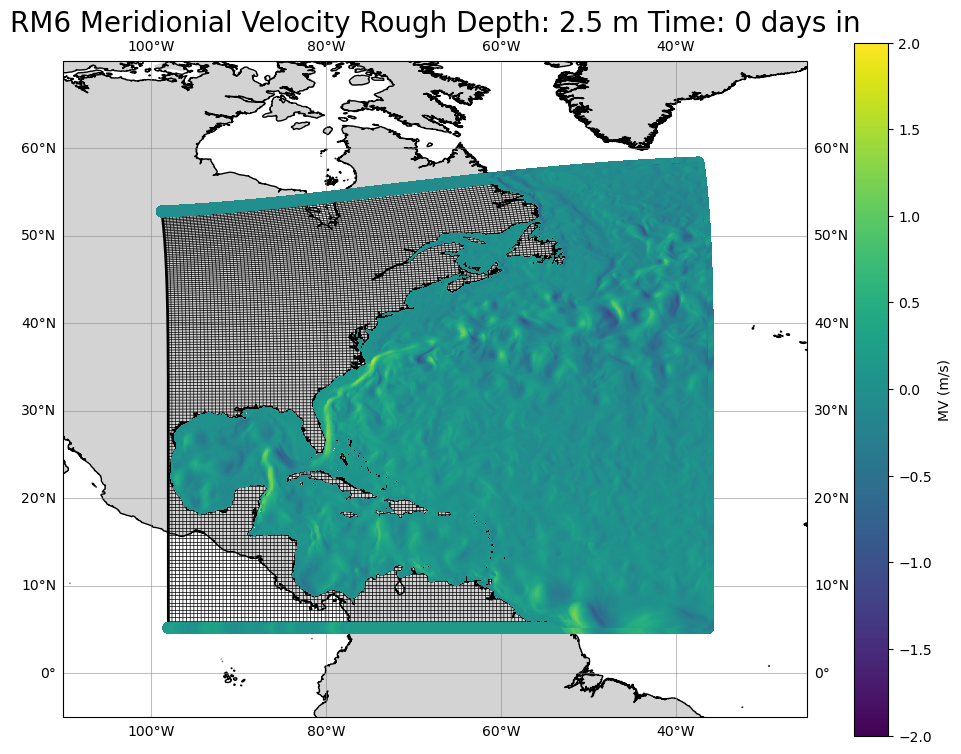

In [24]:
# Animation through time
# Skip Factor
k = 10
depth_index = 0


# Plot and save the NWA12 Mesh grid

fig = plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# Add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
ax.coastlines(resolution='10m')  # looks better with resolution='10m'

ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
min_val = -2
max_val = 2
pcolormesh = ax.pcolormesh(rm6_points["v"].vlon, rm6_points["v"].vlat, output_file[var_name_vo][time][depth_index].values, transform=ccrs.PlateCarree(),  vmin = min_val, vmax = max_val, zorder = 3)
plt.colorbar(pcolormesh, ax=ax, orientation='vertical', label='MV (m/s)')



def update_fig(frame_pair):
    depth_index, time = frame_pair
    target_depth = output_file.z_l[depth_index].values
    pcolormesh.set_array(output_file[var_name_vo][time][depth_index].values)
    plt.title('RM6 Meridionial Velocity Rough Depth: {} m Time: {} days in'.format(target_depth, time), fontsize=20) 
    for key in segment_dir_to_num.keys():
        depth_index_boundary= np.abs(rm6_boundary_velocities[key].depth - target_depth).argmin()
        ax.scatter(rm6_coords[key].lon, rm6_coords[key].lat, c=boundary_indexing_map[key](rm6_boundary_velocities[key][variable+"_segment_"+segment_dir_to_num[key]][time][depth_index_boundary]),s = 50, transform=ccrs.PlateCarree(),vmin = min_val, vmax = max_val,  zorder=2)

frame_pairs = [(index, t) for index in range(35) for t in range(5)]

# ani = FuncAnimation(
#     fig,
#     update_fig,
#     frames = frame_pairs,
#     interval = 100,
#     blit = False,
#     )

# ani.save('boundary_depth_v.mp4', writer='ffmpeg', fps=30)


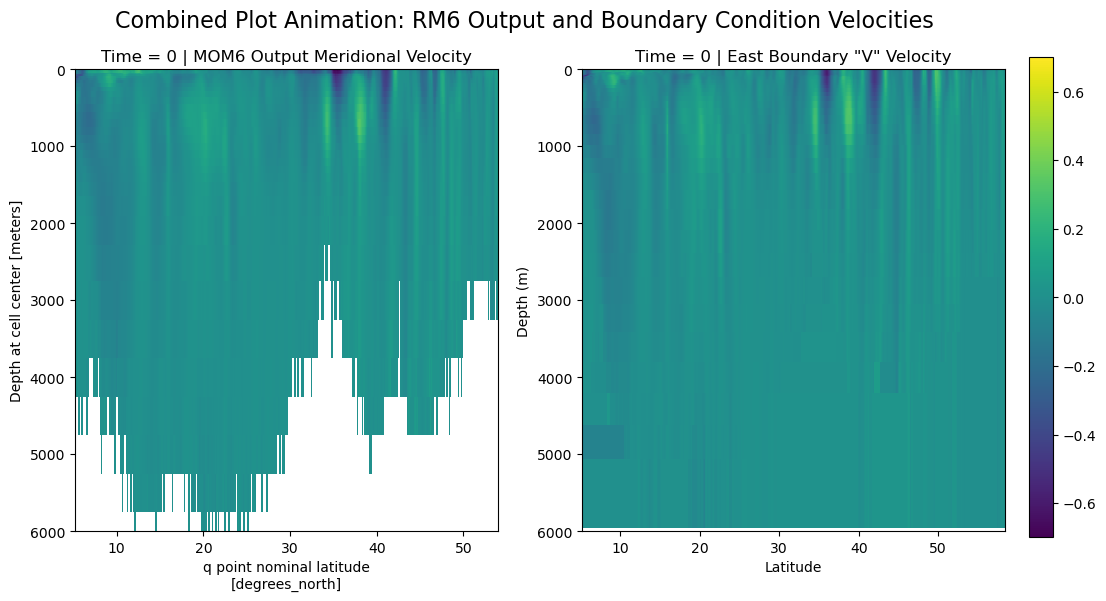

In [81]:
# Constants for plotting

vmin, vmax = -0.7, 0.7
x = -1
depth_max = 6000

# Set up figure and axes
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
cax = fig.add_axes([0.92, 0.1, 0.02, 0.8]) 
fig.suptitle("Combined Plot Animation: RM6 Output and Boundary Condition Velocities", fontsize=16)
rm6_labels =[round(val, 2) for val in rm6_coords["east"].lat.values[::300]] 
gfdl_labels =[round(val, 2) for val in gfdl_coords["east"].lat.values[::300]] 

def update(frame):
    for ax in axes:
        ax.clear()  # Clear previous frame

    # MOM6 MV Plot
    plot_left = output_file.vo[frame,:, :,x].plot(ax=axes[0], vmin=vmin, vmax=vmax)
    axes[0].set_ylim(0,depth_max)
    axes[0].invert_yaxis()
    axes[0].set_title(f"Time = {frame} | MOM6 Output Meridional Velocity")
    
    # RM6 Boundary File
    # Set depth to actual values so the plot doesn't get stretched by vcoord
    rm6_boundary_velocities["east"]["nz_segment_003_v"] = rm6_boundary_velocities["east"].depth.values
    rm6_boundary_velocities["east"]["ny_segment_003"] = rm6_coords["east"].lat.values
    plot_right = rm6_boundary_velocities["east"].v_segment_003[frame,:,:,x].plot(ax=axes[1], vmin=vmin, vmax=vmax)
    axes[1].set_ylim(0,depth_max)
    axes[1].invert_yaxis()
    axes[1].set_title(f"Time = {frame} | East Boundary \"V\" Velocity")
    axes[1].set_xlabel("Latitude")
    axes[1].set_ylabel("Depth (m)")
    
    # Right plot: rm6_boundary_velocities["east"].v_segment_003
    # plot_right_2 = gfdl_boundary_velocities["east"].v_segment_003[frame,:,:,x].plot(ax=axes[2], vmin=vmin, vmax=vmax)
    # axes[2].invert_yaxis()
    # axes[2].set_title(f"Time = {frame} | GFDL East Boundary Meridional Velocity")
    # axes[2].set_xticks(np.arange(0, len(gfdl_coords["east"].lat.values), step=300))
    # axes[2].set_xticklabels(gfdl_labels)
    # axes[2].set_xlabel("Latitude")

    plot_left.colorbar.remove()
    plot_right.colorbar.remove()
    # plot_right_2.colorbar.remove()
    fig.colorbar(plot_left, cax=cax)

# Create animation
n_frames = len(output_file.time)
# anim = FuncAnimation(fig, update, frames=n_frames, interval=200)

# anim.save("visualizations/RM6_East_Boundary_Curtain_Meridional_Velocity.gif")

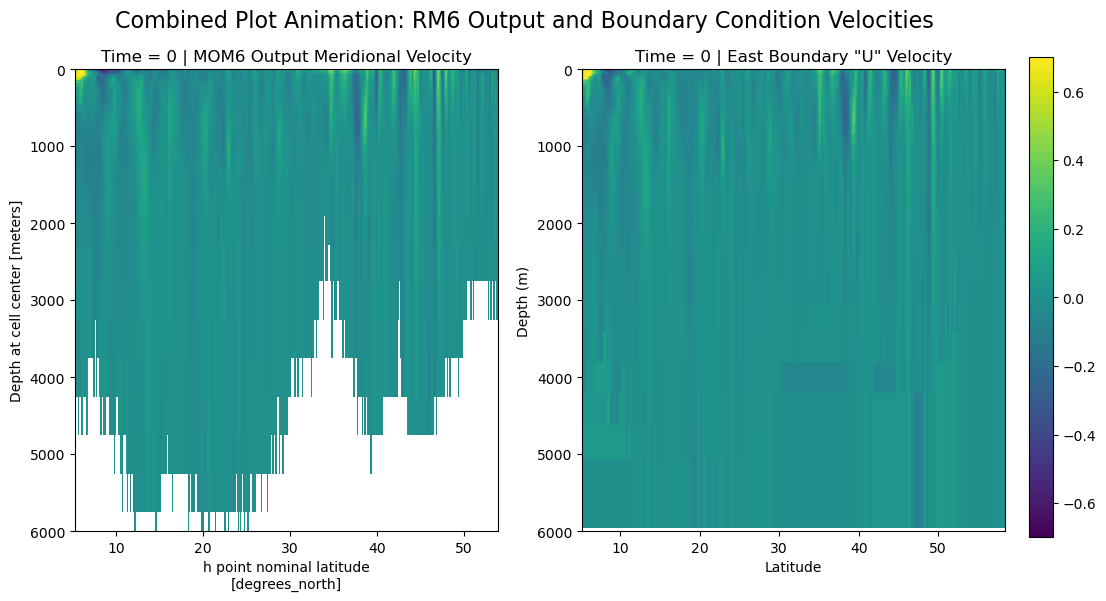

In [82]:
# Constants for plotting

vmin, vmax = -0.7, 0.7
x = -1
depth_max = 6000

# Set up figure and axes
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
cax = fig.add_axes([0.92, 0.1, 0.02, 0.8]) 
fig.suptitle("Combined Plot Animation: RM6 Output and Boundary Condition Velocities", fontsize=16)
rm6_labels =[round(val, 2) for val in rm6_coords["east"].lat.values[::300]] 
gfdl_labels =[round(val, 2) for val in gfdl_coords["east"].lat.values[::300]] 

def update(frame):
    for ax in axes:
        ax.clear()  # Clear previous frame

    # MOM6 MV Plot
    plot_left = output_file.uo[frame,:, :,x].plot(ax=axes[0], vmin=vmin, vmax=vmax)
    axes[0].set_ylim(0,depth_max)
    axes[0].invert_yaxis()
    axes[0].set_title(f"Time = {frame} | MOM6 Output Meridional Velocity")
    
    # RM6 Boundary File
    # Set depth to actual values so the plot doesn't get stretched by vcoord
    rm6_boundary_velocities["east"]["nz_segment_003_u"] = rm6_boundary_velocities["east"].depth.values
    rm6_boundary_velocities["east"]["ny_segment_003"] = rm6_coords["east"].lat.values
    plot_right = rm6_boundary_velocities["east"].u_segment_003[frame,:,:,x].plot(ax=axes[1], vmin=vmin, vmax=vmax)
    axes[1].set_ylim(0,depth_max)
    axes[1].invert_yaxis()
    axes[1].set_title(f"Time = {frame} | East Boundary \"U\" Velocity")
    axes[1].set_xlabel("Latitude")
    axes[1].set_ylabel("Depth (m)")
    
    # Right plot: rm6_boundary_velocities["east"].v_segment_003
    # plot_right_2 = gfdl_boundary_velocities["east"].v_segment_003[frame,:,:,x].plot(ax=axes[2], vmin=vmin, vmax=vmax)
    # axes[2].invert_yaxis()
    # axes[2].set_title(f"Time = {frame} | GFDL East Boundary Meridional Velocity")
    # axes[2].set_xticks(np.arange(0, len(gfdl_coords["east"].lat.values), step=300))
    # axes[2].set_xticklabels(gfdl_labels)
    # axes[2].set_xlabel("Latitude")

    plot_left.colorbar.remove()
    plot_right.colorbar.remove()
    # plot_right_2.colorbar.remove()
    fig.colorbar(plot_left, cax=cax)

# Create animation
n_frames = len(output_file.time)
# anim = FuncAnimation(fig, update, frames=n_frames, interval=200)

# anim.save("visualizations/RM6_East_Boundary_Curtain_Zonal_Velocity.gif")

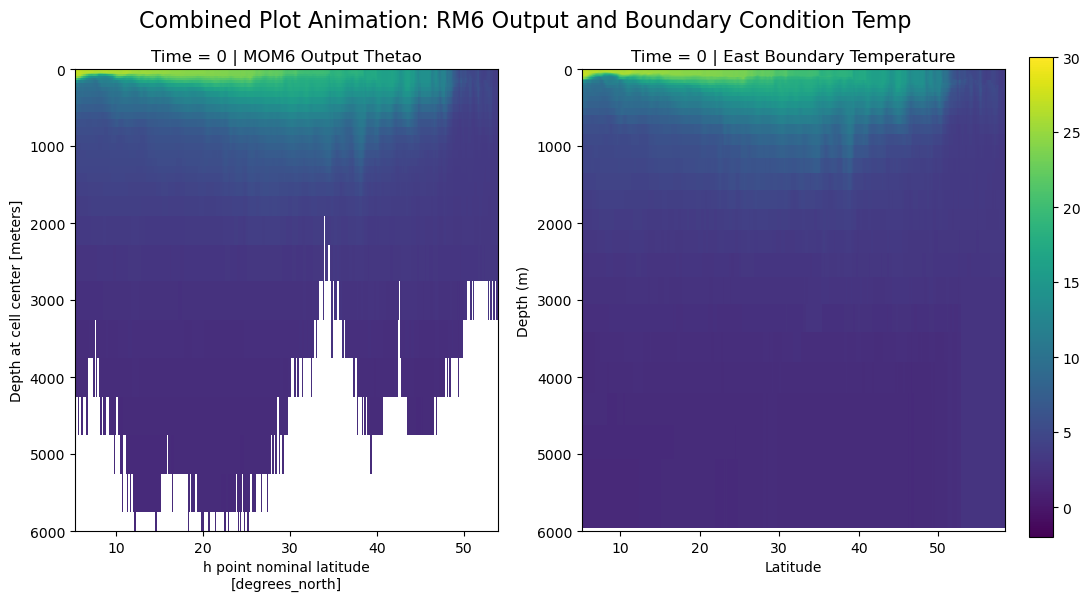

In [88]:
# Constants for plotting

vmin, vmax =-2, 30
x = -1
depth_max = 6000

# Set up figure and axes
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
cax = fig.add_axes([0.92, 0.1, 0.02, 0.8]) 
fig.suptitle("Combined Plot Animation: RM6 Output and Boundary Condition Temp", fontsize=16)
rm6_labels =[round(val, 2) for val in rm6_coords["east"].lat.values[::300]] 
gfdl_labels =[round(val, 2) for val in gfdl_coords["east"].lat.values[::300]] 

def update(frame):
    for ax in axes:
        ax.clear()  # Clear previous frame

    # MOM6 MV Plot
    plot_left = output_file.thetao[frame,:, :,x].plot(ax=axes[0], vmin=vmin, vmax=vmax)
    axes[0].set_ylim(0,depth_max)
    axes[0].invert_yaxis()
    axes[0].set_title(f"Time = {frame} | MOM6 Output Thetao")
    
    # RM6 Boundary File
    # Set depth to actual values so the plot doesn't get stretched by vcoord
    rm6_boundary_velocities["east"]["nz_segment_003_temp"] = rm6_boundary_velocities["east"].depth.values
    rm6_boundary_velocities["east"]["ny_segment_003"] = rm6_coords["east"].lat.values
    plot_right = rm6_boundary_velocities["east"].temp_segment_003[frame,:,:,x].plot(ax=axes[1], vmin=vmin, vmax=vmax)
    axes[1].set_ylim(0,depth_max)
    axes[1].invert_yaxis()
    axes[1].set_title(f"Time = {frame} | East Boundary Temperature")
    axes[1].set_xlabel("Latitude")
    axes[1].set_ylabel("Depth (m)")
    
    # Right plot: rm6_boundary_velocities["east"].v_segment_003
    # plot_right_2 = gfdl_boundary_velocities["east"].v_segment_003[frame,:,:,x].plot(ax=axes[2], vmin=vmin, vmax=vmax)
    # axes[2].invert_yaxis()
    # axes[2].set_title(f"Time = {frame} | GFDL East Boundary Meridional Velocity")
    # axes[2].set_xticks(np.arange(0, len(gfdl_coords["east"].lat.values), step=300))
    # axes[2].set_xticklabels(gfdl_labels)
    # axes[2].set_xlabel("Latitude")

    plot_left.colorbar.remove()
    plot_right.colorbar.remove()
    # plot_right_2.colorbar.remove()
    fig.colorbar(plot_left, cax=cax)

# Create animation
n_frames = len(output_file.time)
# anim = FuncAnimation(fig, update, frames=n_frames, interval=200)

# anim.save("visualizations/RM6_East_Boundary_Curtain_Temperature.gif")

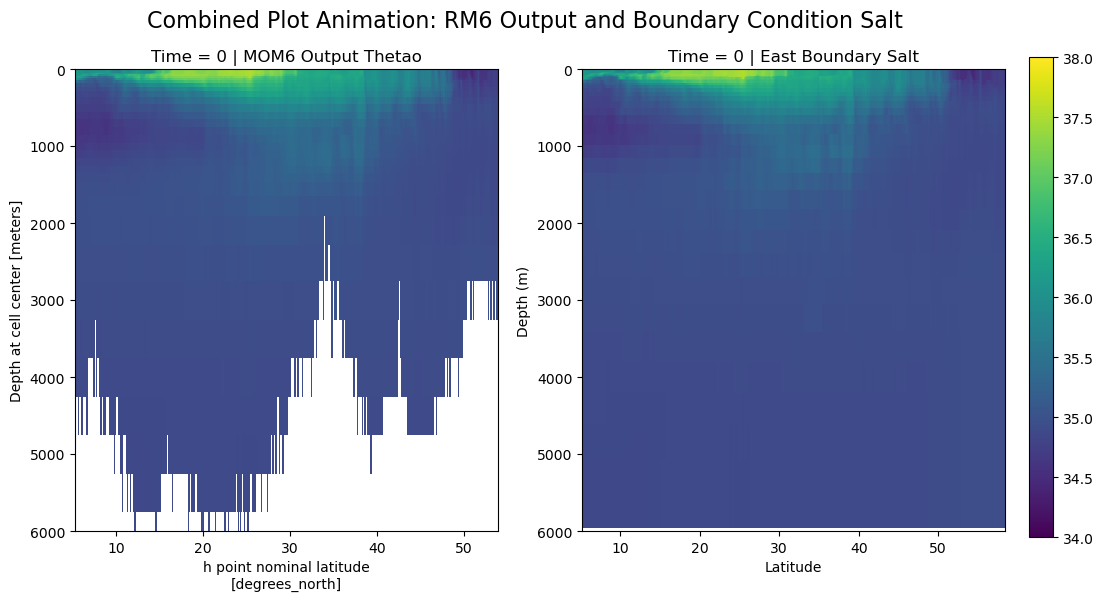

In [94]:
# Constants for plotting

vmin, vmax =34,38
x = -1
depth_max = 6000

# Set up figure and axes
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
cax = fig.add_axes([0.92, 0.1, 0.02, 0.8]) 
fig.suptitle("Combined Plot Animation: RM6 Output and Boundary Condition Salt", fontsize=16)
rm6_labels =[round(val, 2) for val in rm6_coords["east"].lat.values[::300]] 
gfdl_labels =[round(val, 2) for val in gfdl_coords["east"].lat.values[::300]] 

def update(frame):
    for ax in axes:
        ax.clear()  # Clear previous frame

    # MOM6 MV Plot
    plot_left = output_file.so[frame,:, :,x].plot(ax=axes[0], vmin=vmin, vmax=vmax)
    axes[0].set_ylim(0,depth_max)
    axes[0].invert_yaxis()
    axes[0].set_title(f"Time = {frame} | MOM6 Output Thetao")
    
    # RM6 Boundary File
    # Set depth to actual values so the plot doesn't get stretched by vcoord
    rm6_boundary_velocities["east"]["nz_segment_003_salt"] = rm6_boundary_velocities["east"].depth.values
    rm6_boundary_velocities["east"]["ny_segment_003"] = rm6_coords["east"].lat.values
    plot_right = rm6_boundary_velocities["east"].salt_segment_003[frame,:,:,x].plot(ax=axes[1], vmin=vmin, vmax=vmax)
    axes[1].set_ylim(0,depth_max)
    axes[1].invert_yaxis()
    axes[1].set_title(f"Time = {frame} | East Boundary Salt")
    axes[1].set_xlabel("Latitude")
    axes[1].set_ylabel("Depth (m)")
    
    # Right plot: rm6_boundary_velocities["east"].v_segment_003
    # plot_right_2 = gfdl_boundary_velocities["east"].v_segment_003[frame,:,:,x].plot(ax=axes[2], vmin=vmin, vmax=vmax)
    # axes[2].invert_yaxis()
    # axes[2].set_title(f"Time = {frame} | GFDL East Boundary Meridional Velocity")
    # axes[2].set_xticks(np.arange(0, len(gfdl_coords["east"].lat.values), step=300))
    # axes[2].set_xticklabels(gfdl_labels)
    # axes[2].set_xlabel("Latitude")

    plot_left.colorbar.remove()
    plot_right.colorbar.remove()
    # plot_right_2.colorbar.remove()
    fig.colorbar(plot_left, cax=cax)

# Create animation
n_frames = len(output_file.time)
# anim = FuncAnimation(fig, update, frames=n_frames, interval=200)

# anim.save("visualizations/RM6_East_Boundary_Curtain_Salt.gif")

In [45]:


def create_surface_variable_with_boundaries_movie(output_file,output_var_name, boundary_dictionary,boundary_var_name_func, hgrid,  output_mov_name, min_val, max_val, times = None, cmap = "viridis"):
# Plot and save the NWA12 Mesh grid
    if times == None:
        time = 0 # Start
        times = range(len(output_file.time))
    else:
        time = times[0]
    depth_index = 0 # Surface
    fig = plt.figure(figsize=(12,9))
    k = 10

    # the central_longitude parameter tells the projection where to be centered for this axes
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
    gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

    # Add geographic information
    ax.add_feature(cartopy.feature.LAND, fc='lightgray')
    ax.coastlines(resolution='10m')  # looks better with resolution='10m'

    ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
    ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

    ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
    ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
    ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
    ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())

    pcolormesh = ax.pcolormesh(rm6_points["v"].vlon, rm6_points["v"].vlat, output_file[output_var_name][time].values, transform=ccrs.PlateCarree(),  vmin = min_val, vmax = max_val, zorder = 3, cmap = cmap)
    plt.colorbar(pcolormesh, ax=ax, orientation='vertical', label='SSV (m/s)')



    def update_fig(frame_val):
        time = frame_val
        pcolormesh.set_array(output_file[output_var_name][time].values)
        plt.title('RM6 Meridionial Velocity (SSV) Time: {} days in'.format(time), fontsize=20) 
        for key in segment_dir_to_num.keys():
            ax.scatter(rm6_coords[key].lon, rm6_coords[key].lat, c=boundary_indexing_map[key](boundary_dictionary[key][boundary_var_name_func(key)][time][depth_index]),s = 50, transform=ccrs.PlateCarree(),vmin = min_val, vmax = max_val,  zorder=2, cmap = cmap)


    ani = FuncAnimation(
        fig,
        update_fig,
        frames = times,
        interval = 100,
        blit = False,
        )

    ani.save(output_mov_name, writer='ffmpeg', fps=10)

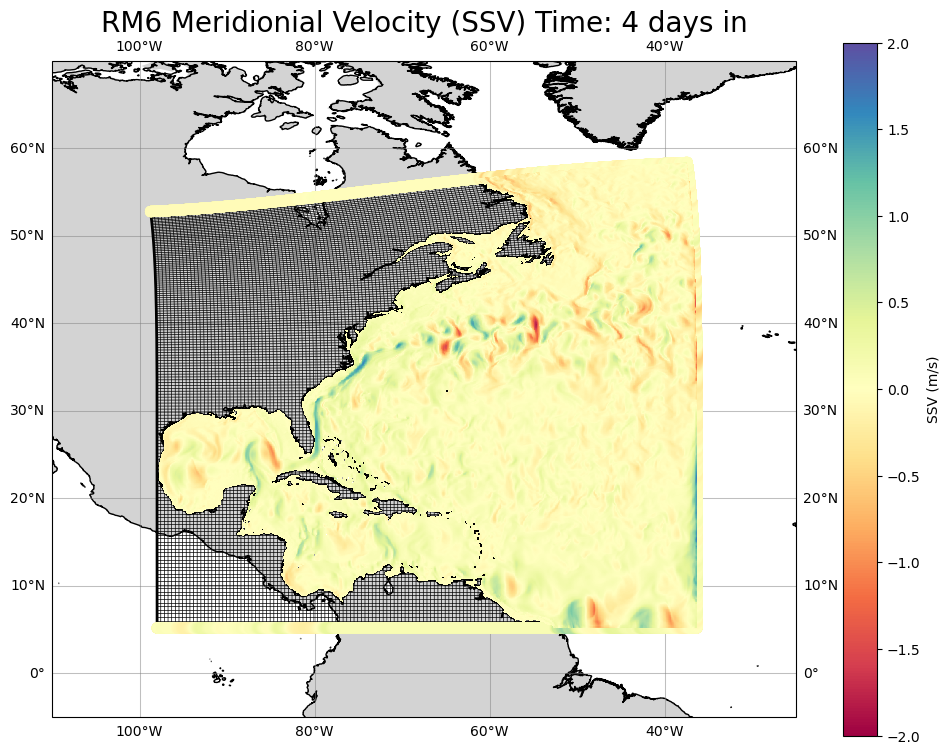

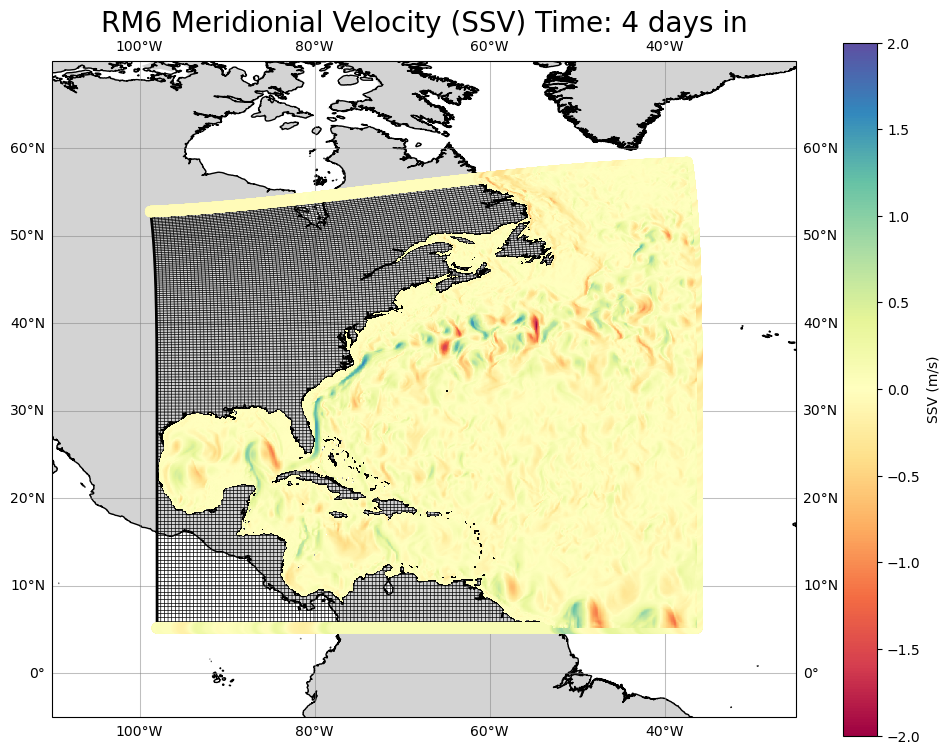

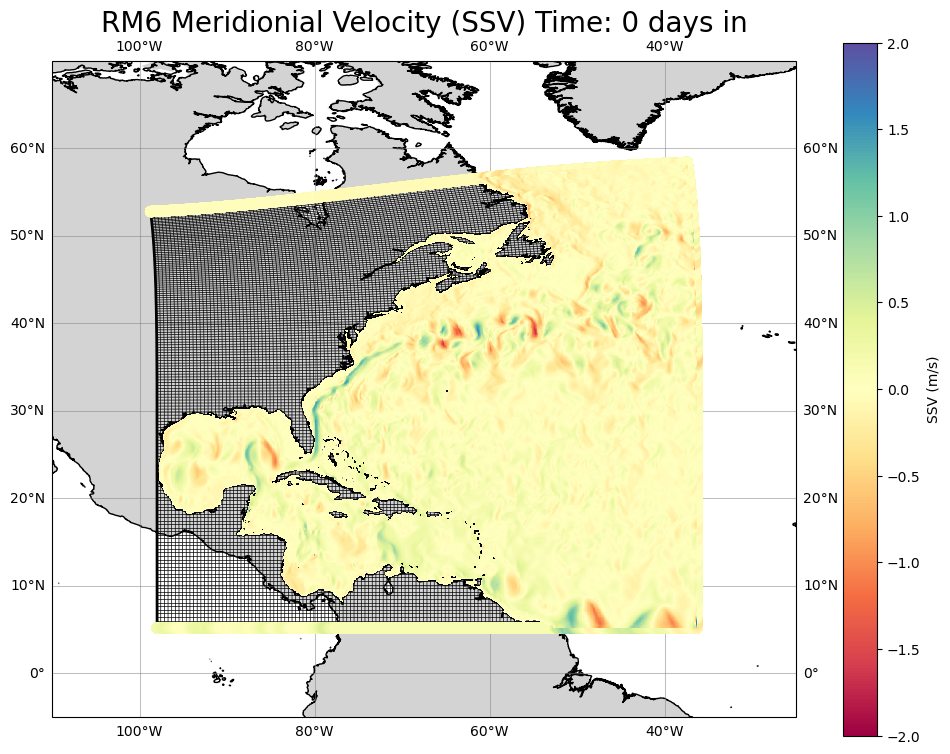

In [46]:
# Animation through time
# Skip Factor

min_val = -2
max_val = 2
output_file_name = Path("nwa12.test.tides.04.mom6.h.sfc.1993-01.nc")
var_name = "SSV"
version = ["orig","no_winds","0_0_1month"]
def boundary_var_name_func(key):
    return "v_segment_"+segment_dir_to_num[key]
for v in version:
    run_path = Path("/glade/derecho/scratch/gmarques/nwa12.test.tides.04/run/"+v)
    output_mov_name = "visualizations/SSV_{}.gif".format(v)
    create_surface_variable_with_boundaries_movie(xr.open_dataset(run_path/output_file_name),var_name,rm6_boundary_velocities,boundary_var_name_func, hgrid, output_mov_name,min_val, max_val , times = None,cmap = "Spectral")